# 01 — Kiểm tra dữ liệu và trích xuất đặc trưng

CSV hồ sơ hiện có 37.438 dòng, 20 cột. Các cell thực hành bên dưới được giữ nguyên. Phần **Pipeline đặc trưng dùng chung** gọi code trong `src/` để tạo bảng đặc trưng và báo cáo chất lượng; phần cuối chia tập và làm EDA trên train. Huấn luyện mô hình nằm ở notebook 02 và 03.


In [1]:
from pathlib import Path
import sys

project_root = Path.cwd()
if not (project_root / "src").is_dir():
    project_root = project_root.parent
if not (project_root / "src").is_dir():
    raise RuntimeError("Mở notebook từ thư mục gốc dự án hoặc notebooks/.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.config import FEATURE_COLUMNS, RANDOM_STATE
print("Project root:", project_root)


Project root: D:\Son_Work_Space\Data_Mining\Social-Media-Bot-Fake-Account-Detection


In [2]:
from src.data import audit_labels

audit = audit_labels()
audit


{'file': 'twitter_human_bots_dataset.csv',
 'rows': 37438,
 'columns': ['',
  'created_at',
  'default_profile',
  'default_profile_image',
  'description',
  'favourites_count',
  'followers_count',
  'friends_count',
  'geo_enabled',
  'id',
  'lang',
  'location',
  'profile_background_image_url',
  'profile_image_url',
  'screen_name',
  'statuses_count',
  'verified',
  'average_tweets_per_day',
  'account_age_days',
  'account_type'],
 'label_counts': {'bot': 12425, 'human': 25013},
 'missing_ids': 0,
 'missing_labels': 0,
 'duplicate_ids': 0,
 'unknown_labels': [],
 'missing_profile_columns': []}

In [3]:
import sys
import pandas as pd

print("Python của notebook:", sys.executable)
print("Phiên bản pandas:", pd.__version__)

data_path = project_root / "dataset" / "twitter_human_bots_dataset.csv"
print("CSV tồn tại:", data_path.is_file())

df = pd.read_csv(data_path, dtype={"id": "string"})

print("Kích thước:", df.shape)
print("Tên cột:", df.columns.tolist())
print("Kiểu dữ liệu của id:", df["id"].dtype)
print("Phân bố nhãn:")
print(df["account_type"].value_counts(dropna=False))

df.head(3)

Python của notebook: D:\Son_Work_Space\Data_Mining\Social-Media-Bot-Fake-Account-Detection\.venv\Scripts\python.exe
Phiên bản pandas: 3.1.0
CSV tồn tại: True
Kích thước: (37438, 20)
Tên cột: ['Unnamed: 0', 'created_at', 'default_profile', 'default_profile_image', 'description', 'favourites_count', 'followers_count', 'friends_count', 'geo_enabled', 'id', 'lang', 'location', 'profile_background_image_url', 'profile_image_url', 'screen_name', 'statuses_count', 'verified', 'average_tweets_per_day', 'account_age_days', 'account_type']
Kiểu dữ liệu của id: string
Phân bố nhãn:
account_type
human    25013
bot      12425
Name: count, dtype: int64


,Unnamed: 0,created_at,default_profile,default_profile_image,description,favourites_count,followers_count,friends_count,geo_enabled,id,lang,location,profile_background_image_url,profile_image_url,screen_name,statuses_count,verified,average_tweets_per_day,account_age_days,account_type
0,0,2016-10-15 21:32:11,False,False,"Blame @xaiax, Inspired by @MakingInvisible, us...",4,1589,4,False,787405734442958848,en,unknown,http://abs.twimg.com/images/themes/theme1/bg.png,http://pbs.twimg.com/profile_images/7874121826...,best_in_dumbest,11041,False,7.870,1403,bot
1,1,2016-11-09 05:01:30,False,False,Photographing the American West since 1980. I ...,536,860,880,False,796216118331310080,en,Estados Unidos,http://abs.twimg.com/images/themes/theme1/bg.png,http://pbs.twimg.com/profile_images/8023296328...,CJRubinPhoto,252,False,0.183,1379,human
2,2,2017-06-17 05:34:27,False,False,Scruffy looking nerf herder and @twitch broadc...,3307,172,594,True,875949740503859204,en,"Los Angeles, CA",http://abs.twimg.com/images/themes/theme1/bg.png,http://pbs.twimg.com/profile_images/1278890453...,SVGEGENT,1001,False,0.864,1159,human


In [4]:
required_columns = [
    "id", "account_type",
    "followers_count", "friends_count", "statuses_count",
    "created_at", "description",
    "account_age_days", "average_tweets_per_day",
]

print("Số giá trị thiếu theo cột:")
print(df[required_columns].isna().sum())

bio = df["description"].astype("string")

missing_bio = bio.isna()
blank_bio = bio.notna() & bio.fillna("").str.strip().eq("")

print("Bio null:", missing_bio.sum())
print("Bio không null nhưng rỗng/chỉ có khoảng trắng:", blank_bio.sum())
print("Tổng bio null hoặc rỗng:", (missing_bio | blank_bio).sum())

Số giá trị thiếu theo cột:
id                           0
account_type                 0
followers_count              0
friends_count                0
statuses_count               0
created_at                   0
description               7257
account_age_days             0
average_tweets_per_day       0
dtype: int64
Bio null: 7257
Bio không null nhưng rỗng/chỉ có khoảng trắng: 0
Tổng bio null hoặc rỗng: 7257


In [5]:
bio_literal = pd.read_csv(
    data_path,
    usecols=["description"],
    dtype={"description": "string"},
    keep_default_na=False,
)["description"]

print("Bio là chuỗi rỗng:", bio_literal.eq("").sum())
print(
    "Bio rỗng hoặc chỉ có khoảng trắng:",
    bio_literal.str.strip().eq("").sum(),
)

print("Nội dung gốc của các bio trước đó bị nhận diện là thiếu:")
print(bio_literal.loc[df["description"].isna()].map(repr).value_counts())

Bio là chuỗi rỗng: 7256
Bio rỗng hoặc chỉ có khoảng trắng: 7256
Nội dung gốc của các bio trước đó bị nhận diện là thiếu:
description
''        7256
'None'       1
Name: count, dtype: Int64


In [6]:
df["description"] = bio_literal.mask(
    bio_literal.eq(""),
    pd.NA,
)

print("Bio thiếu sau khi xử lý:", df["description"].isna().sum())
print("Bio chứa đúng chuỗi 'None':", df["description"].eq("None").sum())
print("Số dòng:", len(df))

Bio thiếu sau khi xử lý: 7256
Bio chứa đúng chuỗi 'None': 1
Số dòng: 37438


In [7]:
duplicate_mask = df["id"].duplicated(keep=False)

print("Số dòng thuộc các ID trùng:", duplicate_mask.sum())
print("Số ID khác nhau bị trùng:", df.loc[duplicate_mask, "id"].nunique())

labels_per_id = df.groupby("id")["account_type"].nunique(dropna=False)
conflicting_ids = labels_per_id[labels_per_id > 1].index

print("Số ID có nhãn mâu thuẫn:", len(conflicting_ids))

if duplicate_mask.any():
    display(
        df.loc[duplicate_mask, ["id", "account_type"]]
        .sort_values("id")
        .head(20)
    )

Số dòng thuộc các ID trùng: 0
Số ID khác nhau bị trùng: 0
Số ID có nhãn mâu thuẫn: 0


## Pipeline đặc trưng dùng chung

Đây là cách chạy chính thức. `load_profiles()` giữ ID và bio dưới dạng chuỗi: 7.256 bio rỗng được coi là thiếu; một bio chứa văn bản `None` được giữ nguyên. Tuổi tài khoản lấy từ nguồn, không tạo `observed_at`. Các lỗi ID/nhãn làm dừng pipeline; số không hợp lệ trở thành giá trị thiếu và được thống kê, không loại dòng.


In [8]:
from src.data import load_profiles
from src.features import run_pipeline
from src.config import RAW_LABELS_PATH, FEATURES_PATH, FEATURE_SUMMARY_PATH

profiles, data_quality = load_profiles(RAW_LABELS_PATH)
print("Kích thước hồ sơ chuẩn hóa:", profiles.shape)
display(profiles[["user_id", "following_count", "account_age_days", "description", "label"]].head())
data_quality


Kích thước hồ sơ chuẩn hóa: (37438, 20)


,user_id,following_count,account_age_days,description,label
0,787405734442958848,4.0,1403.0,"Blame @xaiax, Inspired by @MakingInvisible, us...",1
1,796216118331310080,880.0,1379.0,Photographing the American West since 1980. I ...,0
2,875949740503859204,594.0,1159.0,Scruffy looking nerf herder and @twitch broadc...,0
3,756119643622735875,633.0,1489.0,Wife.Godmother.Friend.Feline Fanatic! Assistan...,0
4,464781334,116.0,3138.0,Loan coach at @mancity & Aspiring DJ,0


{'rows_read': 37438,
 'rows_retained': 37438,
 'rows_removed': 0,
 'removal_reasons': [],
 'source_columns': ['Unnamed: 0',
  'created_at',
  'default_profile',
  'default_profile_image',
  'description',
  'favourites_count',
  'followers_count',
  'friends_count',
  'geo_enabled',
  'id',
  'lang',
  'location',
  'profile_background_image_url',
  'profile_image_url',
  'screen_name',
  'statuses_count',
  'verified',
  'average_tweets_per_day',
  'account_age_days',
  'account_type'],
 'dropped_source_index_columns': ['Unnamed: 0'],
 'identity': {'missing_ids': 0,
  'duplicate_id_rows': 0,
  'duplicate_ids': 0,
  'missing_labels': 0,
  'invalid_labels': 0,
  'conflicting_ids': 0},
 'label_counts': {'human': 25013, 'bot': 12425},
 'numeric_columns': {'followers_count': {'missing': 0,
   'non_numeric': 0,
   'non_finite': 0,
   'negative': 0,
   'fractional': 0,
   'invalid_total': 0,
   'output_missing': 0,
   'valid_zero': 1255},
  'following_count': {'missing': 0,
   'non_numeric':

In [9]:
features, feature_summary = run_pipeline()
print("Đã lưu:", FEATURES_PATH)
print("Báo cáo:", FEATURE_SUMMARY_PATH)
print("Kích thước đặc trưng:", features.shape)
display(features.head())
feature_summary


Đã lưu: D:\Son_Work_Space\Data_Mining\Social-Media-Bot-Fake-Account-Detection\dataset\processed\features.csv
Báo cáo: D:\Son_Work_Space\Data_Mining\Social-Media-Bot-Fake-Account-Detection\reports\feature_summary.json
Kích thước đặc trưng: (37438, 6)


,user_id,follower_following_ratio,posting_frequency,account_age_days,bio_length,label
0,787405734442958848,397.25,7.869565,1403.0,129,1
1,796216118331310080,0.977273,0.182741,1379.0,160,0
2,875949740503859204,0.289562,0.863676,1159.0,81,0
3,756119643622735875,0.816746,0.889187,1489.0,97,0
4,464781334,6497.224138,1.339069,3138.0,36,0


{'data_quality': {'rows_read': 37438,
  'rows_retained': 37438,
  'rows_removed': 0,
  'removal_reasons': [],
  'source_columns': ['Unnamed: 0',
   'created_at',
   'default_profile',
   'default_profile_image',
   'description',
   'favourites_count',
   'followers_count',
   'friends_count',
   'geo_enabled',
   'id',
   'lang',
   'location',
   'profile_background_image_url',
   'profile_image_url',
   'screen_name',
   'statuses_count',
   'verified',
   'average_tweets_per_day',
   'account_age_days',
   'account_type'],
  'dropped_source_index_columns': ['Unnamed: 0'],
  'identity': {'missing_ids': 0,
   'duplicate_id_rows': 0,
   'duplicate_ids': 0,
   'missing_labels': 0,
   'invalid_labels': 0,
   'conflicting_ids': 0},
  'label_counts': {'human': 25013, 'bot': 12425},
  'numeric_columns': {'followers_count': {'missing': 0,
    'non_numeric': 0,
    'non_finite': 0,
    'negative': 0,
    'fractional': 0,
    'invalid_total': 0,
    'output_missing': 0,
    'valid_zero': 1255

In [10]:
import pandas as pd

print("Số dòng loại:", feature_summary["data_quality"]["rows_removed"])
print("CSV nguồn không đổi:", feature_summary["source"]["unchanged"])
print("ID/nhãn khớp:", feature_summary["verification"]["id_label_alignment"])
display(pd.DataFrame(feature_summary["data_quality"]["numeric_columns"]).T)
display(pd.Series(feature_summary["output"]["missing_by_feature"], name="missing"))
feature_summary["posting_frequency_comparison"]


Số dòng loại: 0
CSV nguồn không đổi: True
ID/nhãn khớp: True


,missing,non_numeric,non_finite,negative,fractional,invalid_total,output_missing,valid_zero
followers_count,0,0,0,0,0,0,0,1255
following_count,0,0,0,0,0,0,0,6410
statuses_count,0,0,0,0,0,0,0,56
account_age_days,0,0,0,0,0,0,0,0
average_tweets_per_day,0,0,0,0,0,0,0,72


follower_following_ratio    0
posting_frequency           0
account_age_days            0
bio_length                  0
Name: missing, dtype: int64

{'source_column': 'average_tweets_per_day',
 'assumed_rounding_decimals': 3,
 'absolute_tolerance': 0.0005,
 'floating_point_margin': 1e-12,
 'comparable_rows': 37438,
 'uncomparable_rows': 0,
 'within_rounding_tolerance': 37438,
 'beyond_rounding_tolerance': 0,
 'max_absolute_difference': 0.0005000000000165983,
 'mean_absolute_difference': 0.0002505923629158624,
 'interpretation': 'Comparison only: differences beyond assumed rounding tolerance are reported, not automatically treated as data errors.'}

### Cách diễn giải

- Chỉ bốn cột `FEATURE_COLUMNS` được dùng làm đầu vào mô hình; ID và label dùng để định danh/nhãn.
- Following hoặc tuổi bằng 0 dùng mẫu số 1; thiếu/âm không bị biến thành 0.
- Bio rỗng/null có độ dài 0 là giả định xử lý, vì không phân biệt được rỗng thực sự với chưa thu thập. Unicode được đếm theo code point; giữ khoảng trắng và xuống dòng.
- `posting_frequency` là trung bình bài/ngày trong vòng đời tài khoản. So sánh với nguồn bằng giả định làm tròn 3 chữ số thập phân; sai lệch được thống kê, không tự coi là lỗi.
- Tuổi là giá trị lịch sử của nguồn, không biết chính xác thời điểm quan sát. Không cập nhật theo ngày chạy.
- Công thức, giả định, số liệu thiếu/không hợp lệ và SHA-256 nguồn nằm trong `reports/feature_summary.json`.


## Chia tập dùng chung

Nguồn Kaggle không có split chính thức. `split_features()` chia theo tài khoản, stratify theo nhãn với tỷ lệ `SPLIT_FRACTIONS` (60/20/20) và `RANDOM_STATE`, rồi lưu `user_id → split` vào `dataset/processed/split.csv`. Lần chạy sau dùng lại file này, nên notebook 02–04 thấy cùng một tập train/validation/test. Nếu file không khớp đúng tập `user_id`, hàm báo lỗi thay vì tự tạo split mới.


In [11]:
from src.config import SPLIT_PATH
from src.data import SPLIT_NAMES, split_features

train, validation, test = split_features(features)
print("Split:", SPLIT_PATH)
display(pd.DataFrame({
    name: {"rows": len(part), "share": len(part) / len(features), "bot_share": part["label"].mean()}
    for name, part in zip(SPLIT_NAMES, (train, validation, test))
}).T)


Split: D:\Son_Work_Space\Data_Mining\Social-Media-Bot-Fake-Account-Detection\dataset\processed\split.csv


,rows,share,bot_share
train,22462.0,0.599979,0.331894
validation,7488.0,0.200011,0.331864
test,7488.0,0.200011,0.331864


## EDA trên tập train

Phần này **chỉ dùng tập train**; validation và test không tham gia. Bảng tóm tắt gồm trung vị theo nhãn, độ lệch trước và sau `log1p`, tỷ lệ giá trị 0 và ROC-AUC khi xếp hạng bằng riêng từng đặc trưng. ROC-AUC dưới 0,5 nghĩa là bot có xu hướng mang giá trị **thấp hơn** người thật; càng xa 0,5 thì đặc trưng đơn lẻ càng phân biệt được hai lớp.

In [12]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import roc_auc_score

from src.config import FEATURE_COLUMNS, FIGURES_DIR

eda_X = train[list(FEATURE_COLUMNS)].astype("float64")
eda_y = train["label"].to_numpy()

display(pd.DataFrame([{
    "feature": column,
    "median_human": eda_X.loc[eda_y == 0, column].median(),
    "median_bot": eda_X.loc[eda_y == 1, column].median(),
    "max": eda_X[column].max(),
    "skew": eda_X[column].skew(),
    "skew_log1p": np.log1p(eda_X[column]).skew(),
    "zero_share": eda_X[column].eq(0).mean(),
    "single_feature_roc_auc": roc_auc_score(eda_y, eda_X[column]),
} for column in FEATURE_COLUMNS]).round(3))

,feature,median_human,median_bot,max,skew,skew_log1p,zero_share,single_feature_roc_auc
0,follower_following_ratio,1.645,1.000,5.547370e+07,83.940,1.599,0.032,0.392
1,posting_frequency,2.433,0.808,1.269055e+03,23.657,1.097,0.001,0.333
2,account_age_days,3391.000,2876.000,5.158000e+03,-0.537,-1.228,0.000,0.361
3,bio_length,74.000,35.000,1.900000e+02,0.292,-1.015,0.193,0.338


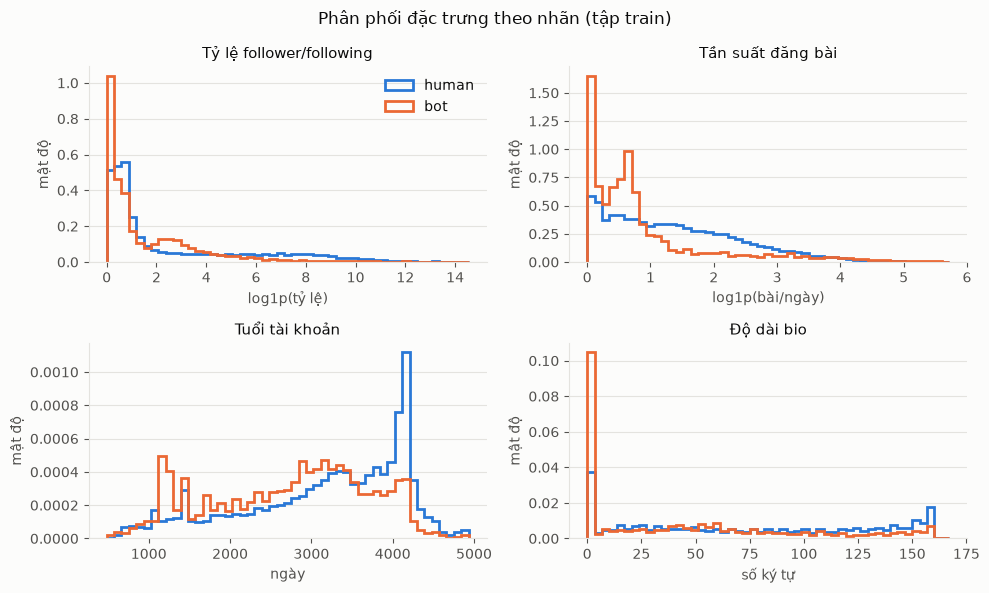

In [13]:
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": MUTED, "axes.edgecolor": GRID, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "grid.color": GRID,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11,
})
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

panels = {
    "follower_following_ratio": ("Tỷ lệ follower/following", "log1p(tỷ lệ)", True),
    "posting_frequency": ("Tần suất đăng bài", "log1p(bài/ngày)", True),
    "account_age_days": ("Tuổi tài khoản", "ngày", False),
    "bio_length": ("Độ dài bio", "số ký tự", False),
}
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for ax, (column, (title, xlabel, use_log)) in zip(axes.ravel(), panels.items()):
    values = np.log1p(eda_X[column]) if use_log else eda_X[column]
    bins = np.linspace(values.min(), values.quantile(0.999), 50)
    for label, name, color in ((0, "human", "#2a78d6"), (1, "bot", "#eb6834")):
        ax.hist(values[eda_y == label], bins=bins, density=True, histtype="step",
                linewidth=2, color=color, label=name)
    ax.set(title=title, xlabel=xlabel, ylabel="mật độ")
    ax.grid(axis="y", linewidth=0.8)
    ax.set_axisbelow(True)
axes[0, 0].legend(frameon=False)
fig.suptitle("Phân phối đặc trưng theo nhãn (tập train)", fontsize=12)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_feature_distributions_train.png", dpi=150, bbox_inches="tight")
plt.show()

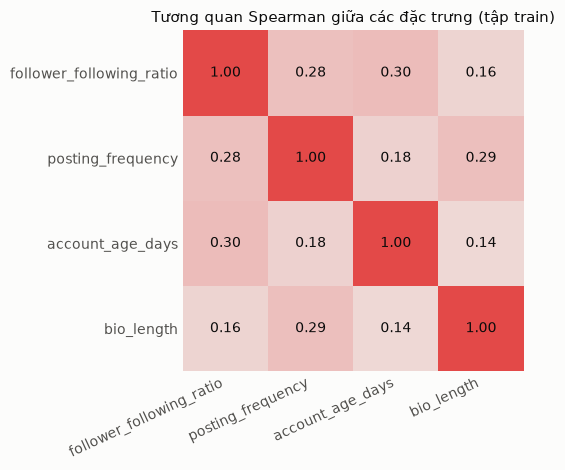

In [14]:
correlation = eda_X.corr(method="spearman")
cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list(
    "blue_red", ["#2a78d6", "#f0efec", "#e34948"],
)
fig, ax = plt.subplots(figsize=(6.2, 4.8))
ax.imshow(correlation, cmap=cmap, vmin=-1, vmax=1)
for (i, j), value in np.ndenumerate(correlation.to_numpy()):
    ax.text(j, i, f"{value:.2f}", ha="center", va="center", color=INK, fontsize=10)
ax.set_xticks(range(len(correlation)), correlation.columns, rotation=25, ha="right")
ax.set_yticks(range(len(correlation)), correlation.index)
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_title("Tương quan Spearman giữa các đặc trưng (tập train)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_spearman_correlation_train.png", dpi=150, bbox_inches="tight")
plt.show()

### Nhận xét từ EDA trên train

- **Hai đặc trưng lệch rất mạnh:** độ lệch của `follower_following_ratio` là 83,9 và của `posting_frequency` là 23,7; sau `log1p` còn 1,6 và 1,1. Mô hình nhạy với thang đo cần xử lý điều này; mô hình cây thì không.
- **`log1p` không có lợi cho hai đặc trưng còn lại:** độ lệch của `account_age_days` đổi từ -0,54 thành -1,23, của `bio_length` từ 0,29 thành -1,02. Pipeline One-Class SVM hiện áp dụng `log1p` cho cả bốn đặc trưng. Đây là giới hạn đã biết: phát hiện này đến sau khi test đã được dùng, nên cấu hình không được đổi lại.
- **Bot có giá trị thấp hơn ở cả bốn đặc trưng:** trung vị tỷ lệ follower/following 1,00 so với 1,65; tần suất đăng 0,81 so với 2,43 bài/ngày; tuổi 2.876 so với 3.391 ngày; bio 35 so với 74 ký tự. ROC-AUC theo từng đặc trưng đều dưới 0,5 (0,333 đến 0,392). Điều này khớp với notebook 02: giá trị rất cao mới là điểm ngoại lai, và các điểm đó không phải bot.
- **Từng đặc trưng đơn lẻ chỉ phân biệt ở mức vừa phải:** tốt nhất là `posting_frequency`, tương đương ROC-AUC 0,667 nếu đảo chiều, thấp hơn nhiều so với 0,863 khi Gradient Boosting kết hợp cả bốn (notebook 04).
- **Không có đặc trưng dư thừa rõ ràng:** tương quan Spearman giữa các cặp chỉ từ 0,14 đến 0,30, nên giữ cả bốn.
- **Phân phối có các đỉnh riêng:** bot tập trung ở bio rỗng và quanh tuổi 1.100 đến 1.400 ngày; người thật có đỉnh lớn quanh 4.000 đến 4.200 ngày.

EDA này được viết sau khi đã huấn luyện mô hình và không làm thay đổi cấu hình nào. Bước `log1p` được chọn trước đó khi xem thống kê mô tả trên **toàn bộ** dữ liệu, chưa tách riêng train; EDA này kiểm tra lại quyết định đó chỉ trên train.